<a href="https://colab.research.google.com/github/HarshXtech/AI-dependency-research/blob/main/AI_dependency_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI USAGE & DEPENDENCY RESEARCH - Complete Statistical Analysis


In [1]:
# Importing Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import shapiro, ttest_ind

In [2]:
# Loading data

path = "/content/drive/MyDrive/datasets/AI-dependency-survey-respondents - Form Responses 1.csv"

df = pd.read_csv(path)

print("Dataset Information")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("Questions: ")
for i, col in enumerate(df.columns):
    print(i, ":", col)

Dataset Information
Rows: 35
Columns: 21
Questions: 
0 : Timestamp
1 : Q1. What is your age? 
2 : Q2. What is your current level of study?
3 : Q3. How frequently do you use AI tools?
4 : Q4. Approximately how much time do you spend using AI tools in a typical week?
5 : Q5. Which AI tools do you regularly use?
6 : Q6. How often do you use AI to help you understand or learn a new concept?
7 : Q7. How often do you use AI while coding or debugging programs?
8 : Q8. How often do you use AI to write, rewrite, or improve written content such as assignments, posts, emails, or articles?
9 : Q9. How often do you use AI to summarize books, articles, notes, lectures, or other study material?
10 : Q10. How often do you use AI to find, explain, or simplify information while reading?
11 : Q11. How often do you use AI for exam or test preparation?
12 : Q12. How often do you use AI for job or internship preparation, such as resumes, applications, job descriptions, or career advice?
13 : Q13. How often 

In [3]:
# Data Quality

print("MISSING VALUES")

missing = df.isnull().sum()

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

MISSING VALUES
Total missing values: 1
Duplicate rows: 0


In [4]:
# Question Columns

q1 = 'Q1. What is your age? '
q2 = 'Q2. What is your current level of study?'

q3 = 'Q3. How frequently do you use AI tools?'
q4 = 'Q4. Approximately how much time do you spend using AI tools in a typical week?'
q5 = 'Q5. Which AI tools do you regularly use?'

usage_questions = [
    'Q6. How often do you use AI to help you understand or learn a new concept?',
    'Q7. How often do you use AI while coding or debugging programs?',
    'Q8. How often do you use AI to write, rewrite, or improve written content such as assignments, posts, emails, or articles?',
    'Q9. How often do you use AI to summarize books, articles, notes, lectures, or other study material?',
    'Q10. How often do you use AI to find, explain, or simplify information while reading?',
    'Q11. How often do you use AI for exam or test preparation?',
    'Q12. How often do you use AI for job or internship preparation, such as resumes, applications, job descriptions, or career advice?',
    'Q13. How often do you use AI for interview preparation, such as generating questions, practicing answers, or conducting mock interviews?'
]
dependency_questions = [
    'Q14. I use AI even when I could complete the task myself.',
    'Q15. When I get stuck while learning, AI is usually my first source of help.',
    'Q16. I find it difficult to complete some learning tasks without AI.',
    'Q17. I sometimes accept AI-generated answers without fully checking or understanding them.',
    'Q18. Using AI has reduced the amount of effort I personally put into some learning tasks.',
    'Q19. I feel less confident about solving difficult problems when AI is not available.'
]

q20 = 'Q20. I make sure I understand a topic myself even when AI provides me with an answer.'

## Descriptive Statistics

In [5]:
# Basic Demographic Analysis

print('-------Age Details-------')
print(df[q1].value_counts(normalize=True, dropna=False).mul(100).round(2))


print("\n------Level Of Study-----")
print(df[q2].value_counts(normalize=True).mul(100).round(2))

-------Age Details-------
Q1. What is your age? 
22-24          45.71
19-21          28.57
25 or above    22.86
18 or below     2.86
Name: proportion, dtype: float64

------Level Of Study-----
Q2. What is your current level of study?
Postgraduate     60.00
Undergraduate    28.57
Other            11.43
Name: proportion, dtype: float64


In [6]:
# General AI Usage:

print("Percentages:\n")
print(df[q3].value_counts(normalize=True).mul(100).round(2))

Percentages:

Q3. How frequently do you use AI tools?
Often         54.29
Very often    25.71
sometimes     20.00
Name: proportion, dtype: float64


In [7]:
# Weekly AI usage:

print("Percentages:\n")
print(df[q4].value_counts(normalize=True).mul(100).round(2))

Percentages:

Q4. Approximately how much time do you spend using AI tools in a typical week?
3-5 hours             38.24
1-3 hours             29.41
5-10 hours            20.59
More than 10 hours     8.82
Less than an hour      2.94
Name: proportion, dtype: float64


In [8]:
# AI tools used

print(df[q5].value_counts(normalize=True).mul(100).round(2))

Q5. Which AI tools do you regularly use?
ChatGPT          68.57
Claude           20.00
Google Gemini    11.43
Name: proportion, dtype: float64


In [9]:
# Likert Encoding

likert_map = {
    "Never": 1,
    "Rarely": 2,
    "Sometimes": 3,
    "Often": 4,
    "Very often": 5
}

agreement_map = {
    "Strongly disagree": 1,
    "Disagree": 2,
    "Neutral": 3,
    "Agree": 4,
    "Strongly agree": 5
}


# Encoding usage questions
for col in usage_questions:
    df[col + "_score"] = df[col].map(likert_map)

# Encoding dependency questions
for col in dependency_questions:
    df[col + "_score"] = df[col].map(agreement_map)

# Encoding Q20 separately (because it's a reverse question)
df[q20 + "_score"] = df[q20].map(agreement_map)

In [10]:
# Creating AI usage index

usage_score_cols = [col + "_score" for col in usage_questions
]

df["AI_Usage_Index"] = df[usage_score_cols].mean(axis=1)

In [11]:
# Creating AI Dependency Index

dependency_score_cols = [
    col + "_score"
    for col in dependency_questions
]

df["AI_Dependency_Index"] = (
    df[dependency_score_cols]
    .mean(axis=1)
)

In [12]:
# Independent Learning Score as per Q-20

df["Independent_Learning_Score"] = df[q20 + "_score"]

In [13]:
# Descriptive Statistic Analysis

research_variables = [
    "AI_Usage_Index",
    "AI_Dependency_Index",
    "Independent_Learning_Score"
]

desc = df[research_variables].describe().T

desc["variance"] = df[research_variables].var()

desc

,count,mean,std,min,25%,50%,75%,max,variance
AI_Usage_Index,35.0,3.753571,0.668683,2.375000,3.25,3.75,4.250000,5.0,0.447138
AI_Dependency_Index,35.0,3.390476,0.599486,2.166667,3.00,3.50,3.666667,5.0,0.359384
Independent_Learning_Score,35.0,3.771429,1.059570,1.000000,3.50,4.00,4.000000,5.0,1.122689


In [14]:
# Average score of individual questions

print("\nMeasuring Usage: ")

usage_means = (
    df[usage_score_cols]
    .mean()
    .sort_values(ascending=False)
)

for col, value in usage_means.items():
    print(f"{col[:60]} : {value:.2f}")

print("\nMeasuring Dependency: ")

dependency_means = (
    df[dependency_score_cols]
    .mean()
    .sort_values(ascending=False)
)

for col, value in dependency_means.items():
    print(f"{col[:60]} : {value:.2f}")


Measuring Usage: 
Q6. How often do you use AI to help you understand or learn  : 4.03
Q13. How often do you use AI for interview preparation, such : 4.00
Q11. How often do you use AI for exam or test preparation?_s : 3.91
Q12. How often do you use AI for job or internship preparati : 3.83
Q9. How often do you use AI to summarize books, articles, no : 3.63
Q7. How often do you use AI while coding or debugging progra : 3.57
Q8. How often do you use AI to write, rewrite, or improve wr : 3.57
Q10. How often do you use AI to find, explain, or simplify i : 3.49

Measuring Dependency: 
Q15. When I get stuck while learning, AI is usually my first : 4.00
Q18. Using AI has reduced the amount of effort I personally  : 3.69
Q16. I find it difficult to complete some learning tasks wit : 3.43
Q19. I feel less confident about solving difficult problems  : 3.34
Q14. I use AI even when I could complete the task myself._sc : 3.23
Q17. I sometimes accept AI-generated answers without fully c : 2.66


In [15]:
# Shapiro-wilk test to check normality

for variable in research_variables:

    data = df[variable].dropna()

    statistic, p = shapiro(data)

    print(
        f"{variable}: "
        f"W={statistic:.3f}, "
        f"p={p:.4f}"
    )

AI_Usage_Index: W=0.979, p=0.7390
AI_Dependency_Index: W=0.956, p=0.1787
Independent_Learning_Score: W=0.773, p=0.0000


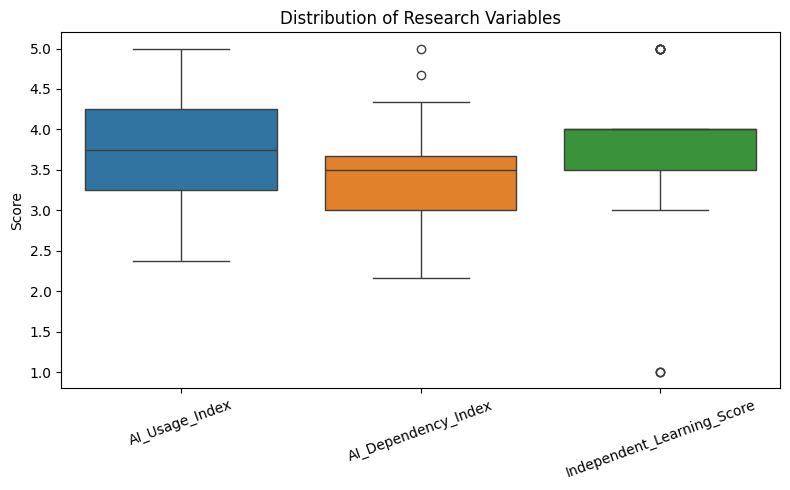

In [16]:
# Boxplot of research variables - to get 5 number summary and outlier information.

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df[research_variables]
)

plt.title("Distribution of Research Variables")

plt.xticks(
    rotation=20
)

plt.ylabel("Score")

plt.tight_layout()

plt.show()

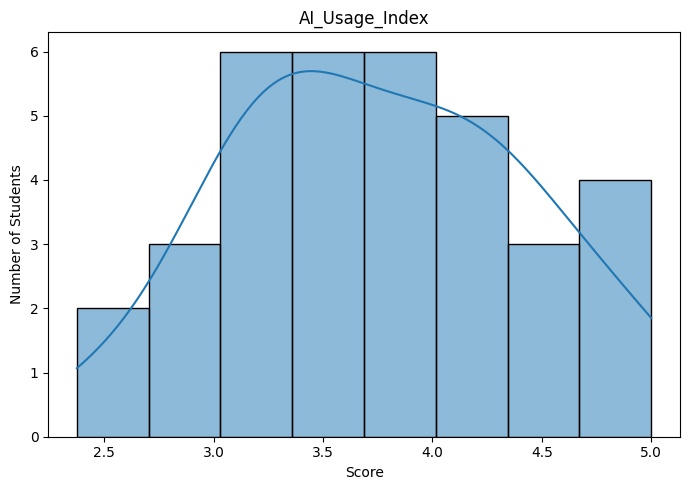

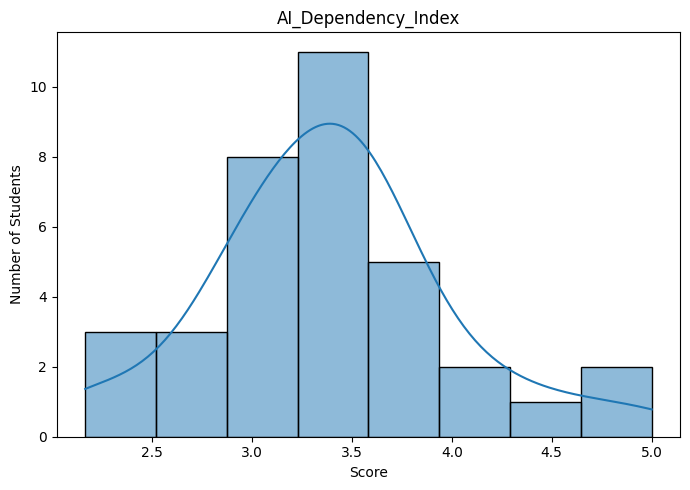

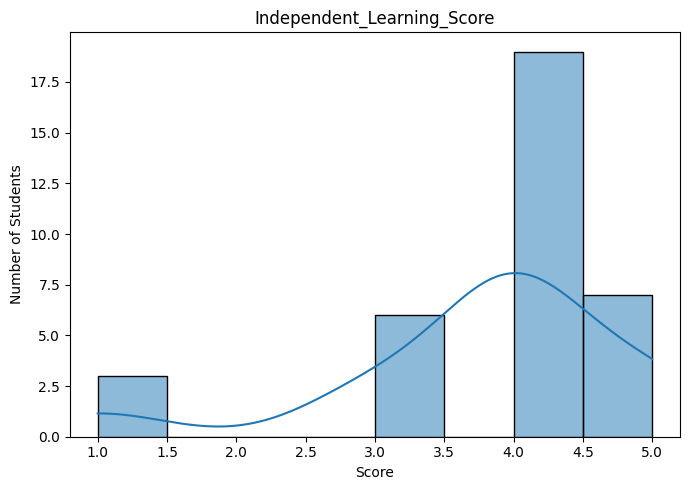

In [17]:
# Histograms - to check frequency and distributions

for variable in research_variables:

    plt.figure(figsize=(7, 5))

    sns.histplot(
        df[variable].dropna(),
        bins=8,
        kde=True
    )

    plt.title(variable)

    plt.xlabel("Score")

    plt.ylabel("Number of Students")

    plt.tight_layout()

    plt.show()

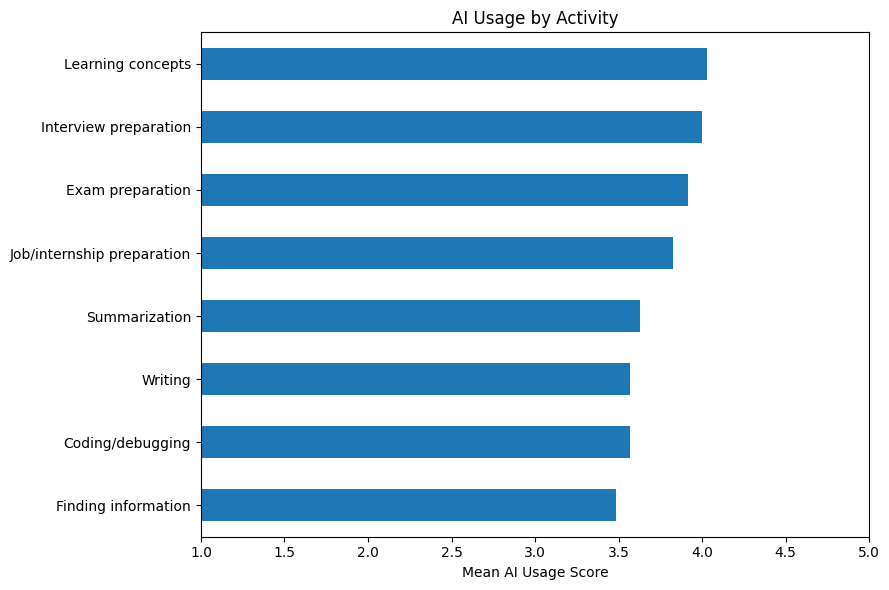

In [18]:
# AI Usage by activity

activity_labels = {
    usage_questions[0]: "Learning concepts",
    usage_questions[1]: "Coding/debugging",
    usage_questions[2]: "Writing",
    usage_questions[3]: "Summarization",
    usage_questions[4]: "Finding information",
    usage_questions[5]: "Exam preparation",
    usage_questions[6]: "Job/internship preparation",
    usage_questions[7]: "Interview preparation"
}

activity_means = {}

for col in usage_questions:

    activity_means[
        activity_labels[col]
    ] = df[col + "_score"].mean()

activity_df = (
    pd.Series(activity_means)
    .sort_values()
)

plt.figure(figsize=(9, 6))

activity_df.plot(
    kind="barh"
    )

plt.xlabel("Mean AI Usage Score")

plt.title("AI Usage by Activity")

plt.xlim(1, 5)

plt.tight_layout()

plt.show()

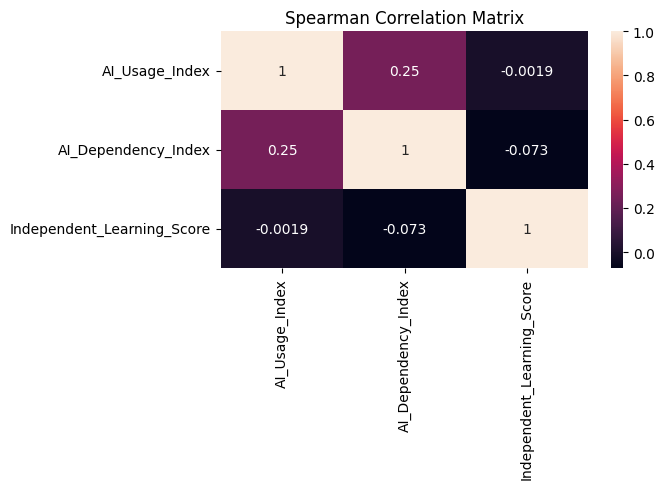

In [19]:
# Getting Correlation Matrix

corr_variables = [
    "AI_Usage_Index",
    "AI_Dependency_Index",
    "Independent_Learning_Score"
]

spearman_matrix = df[corr_variables].corr(
    method="spearman"
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    spearman_matrix,
    annot=True,
)

plt.title("Spearman Correlation Matrix")

plt.tight_layout()

plt.show()

In [20]:
# Dependency by education level

group_summary = (
    df.groupby(q2)["AI_Dependency_Index"]
    .agg([
        "count",
        "mean",
        "median",
        "std"
    ])
    .sort_values("mean", ascending=False)
)

print(group_summary)

                                          count      mean    median       std
Q2. What is your current level of study?                                     
Undergraduate                                10  3.550000  3.500000  0.652866
Other                                         4  3.458333  3.500000  0.209718
Postgraduate                                 21  3.301587  3.333333  0.624987


In [21]:
# Usage by level of study

usage_group_summary = (
    df.groupby(q2)["AI_Usage_Index"]
    .agg([
        "count",
        "mean",
        "median",
        "std"
    ])
    .sort_values("mean", ascending=False)
)

print(usage_group_summary)

                                          count      mean  median       std
Q2. What is your current level of study?                                   
Other                                         4  4.281250  4.3750  0.482776
Postgraduate                                 21  3.809524  3.8750  0.608044
Undergraduate                                10  3.425000  3.4375  0.734091


In [24]:
import pandas as pd
from scipy.stats import ttest_1samp

# Hypothesis: Is mean AI dependency significantly above 3 for entire population?

"""
H0: μ=3
H1: μ>3
"""
dependency_score_columns = [
    col + "_score"
    for col in dependency_questions
]

df["AI_Dependency_Score"] = (
    df[dependency_score_columns]
    .mean(axis=1)
)


# Removing students with missing dependency scores

dependency_scores = (
    df["AI_Dependency_Score"]
    .dropna()
)

# 6. Descriptive statistics

print("Number of students:", len(dependency_scores))
print("Mean:", round(dependency_scores.mean(), 3))
print("Median:", round(dependency_scores.median(), 3))
print("Standard deviation:", round(dependency_scores.std(), 3))
print("Minimum:", round(dependency_scores.min(), 3))
print("Maximum:", round(dependency_scores.max(), 3))


# 7. ONE-SAMPLE T-TEST

# Neutral midpoint of the 1–5 scale
neutral_value = 3

t_stat, p_one_tailed = ttest_1samp(
    dependency_scores,
    popmean=neutral_value,
    alternative='greater'
)


# 8. Converting to ONE-TAILED p-value

# Our alternative hypothesis is:
#
# H1: mean dependency > 3
#
# Therefore, if t is positive:
# one-tailed p = two-tailed p / 2
# 9. hypothesis test results

print("\nH0: Mean AI dependency = 3")
print("H1: Mean AI dependency > 3")

print("\nResults:")
print("t-statistic:", round(t_stat, 4))
print("One-tailed p-value:", round(p_one_tailed, 4))


alpha = 0.05

print("\nSignificance level:", alpha)

if p_one_tailed < alpha:

    print("\nDecision: REJECT H0")

    print(
        "There is statistically significant evidence that "
        "the population mean AI-dependency score is greater than 3."
    )

else:

    print("\nDecision: FAIL TO REJECT H0")
    print(
        "There is insufficient statistical evidence to conclude "
        "that the population mean AI-dependency score is greater than 3."
    )

Number of students: 35
Mean: 3.39
Median: 3.5
Standard deviation: 0.599
Minimum: 2.167
Maximum: 5.0

H0: Mean AI dependency = 3
H1: Mean AI dependency > 3

Results:
t-statistic: 3.8534
One-tailed p-value: 0.0002

Significance level: 0.05

Decision: REJECT H0
There is statistically significant evidence that the population mean AI-dependency score is greater than 3.
